# Лабораторна робота №6
## Робота з відкритим програмним кодом
#### ФБ-31 Аль-Фітурі Асія
**Мета роботи:** Отримати навички використання існуючого програмного коду.

**Обрана наукова стаття:** Segment Anything (Kirillov et al., 2023).

**Посилання на статтю:** https://arxiv.org/abs/2304.02643

**Офіційний GitHub:** https://github.com/facebookresearch/segment-anything

У цій лабораторній роботі я розгляну алгоритм Segment Anything Model (SAM), який використовується для сегментації об'єктів на зображеннях. Я ознайомлюся з основною ідеєю статті, розберуся в готовому коді та перевірю роботу моделі на прикладі зображення.

### Посилання на власний GitHub
https://github.com/asiaelfiturid/machine-learning-lab6-SAM


### Опис наукової статті


**Рік публікації:** 2023



У статті автори представили модель Segment Anything Model (SAM), призначену для сегментації об'єктів на зображеннях. Основна ідея полягає в тому, що модель може виділяти об'єкти за підказками користувача, наприклад точками або прямокутними рамками.

SAM складається з трьох основних частин: image encoder, який обробляє зображення, prompt encoder, який обробляє підказки, та mask decoder, який створює маску об'єкта.

Новизна підходу полягає в можливості застосовувати одну попередньо навчену модель для сегментації різних об'єктів без окремого донавчання під кожне нове зображення. Для навчання автори створили великий набір даних SA-1B, який містить понад 1 мільярд масок для приблизно 11 мільйонів зображень.
У статті показано, що SAM може виконувати сегментацію на нових даних без додаткового навчання (zero-shot) та в багатьох задачах демонструє результати, конкурентні з попередніми підходами.

### 1. Підготовка бібліотек

In [87]:

import matplotlib.pyplot as plt
import sys
import platform

print("Версія Python:", sys.version.split()[0])
print("Операційна система:", platform.system())

try:
    import torch
    print("Версія PyTorch:", torch.__version__)
    print("CUDA доступна:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("Відеокарта:", torch.cuda.get_device_name(0))
except ImportError:
    print("PyTorch ще не встановлено")


Версія Python: 3.12.10
Операційна система: Windows
Версія PyTorch: 2.15.0+cpu
CUDA доступна: False


In [88]:
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [89]:

import torch

print("Версія PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())


Версія PyTorch: 2.15.0+cpu
CUDA доступна: False


In [90]:

# Встановлюю бібліотеки для роботи з моделлю SAM
%pip install segment-anything opencv-python matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [91]:

# Перевіряю встановлені бібліотеки
import numpy as np
import cv2
import torch
from segment_anything import sam_model_registry, SamPredictor

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("SAM імпортовано успішно")


NumPy: 1.26.4
OpenCV: 4.10.0
PyTorch: 2.15.0+cpu
SAM імпортовано успішно


In [92]:

# Перевіряю наявність файлу моделі
from pathlib import Path

model_path = Path("sam_vit_b_01ec64.pth")

print("Файл знайдено:", model_path.exists())

if model_path.exists():
    print("Розмір файлу:", round(model_path.stat().st_size / 1024**2, 1), "МБ")


Файл знайдено: True
Розмір файлу: 357.7 МБ


In [93]:
 
# Завантажую модель SAM ViT-B на процесор
device = "cpu"

sam = sam_model_registry["vit_b"](
    checkpoint=str(model_path)
)

sam.to(device=device)
sam.eval()

print("Модель SAM ViT-B успішно завантажена!")
print("Пристрій:", device)


Модель SAM ViT-B успішно завантажена!
Пристрій: cpu


In [94]:

from pathlib import Path

# Перевіряю фотографії в папці лабораторної
folder = Path(r"E:\7 семестр\методи машинного навчання\лаб 6")

for file in folder.iterdir():
    if file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        print(repr(file.name))


'фото1.jpg'
'фото2.jpg'
'фото3.jpg'


In [95]:

from pathlib import Path

print("Поточна папка:", Path.cwd())

print("\nФайли в поточній папці:")
for file in Path.cwd().iterdir():
    print(file.name)

print("\nФотографії в папці лабораторної:")
image_folder = Path.cwd() / "7 семестр" / "методи машинного навчання" / "лаб 6"

if image_folder.exists():
    for file in image_folder.iterdir():
        print(file.name)


Поточна папка: e:\7 семестр\методи машинного навчання\лаб 6

Файли в поточній папці:
lab6.ipynb
sam_vit_b_01ec64.pth
фото1.jpg
фото2.jpg
фото3.jpg

Фотографії в папці лабораторної:


### 2. Підготовка фотографії

Я взяла фотографію двох котів. Далі перевела кольори у формат RGB та зменшила фотографію до 800 × 600 пікселів, щоб модель працювала швидше на процесорі.

Розмір зображення: (800, 600, 3)


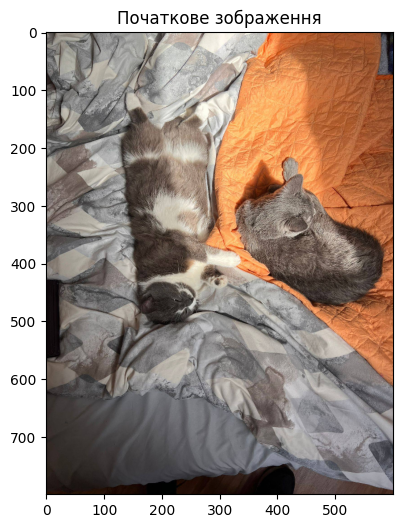

In [96]:

# Завантажую фотографію для сегментації
image_path = "фото1.jpg"

# Читаю файл з підтримкою кириличних назв
img_bgr = cv2.imdecode(
    np.fromfile(image_path, dtype=np.uint8),
    cv2.IMREAD_COLOR
)

if img_bgr is None:
    raise ValueError("Не вдалося відкрити фотографію")

img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Зменшую фотографію до 800 пікселів
h, w = img.shape[:2]
scale = min(1, 800 / max(h, w))

if scale < 1:
    img = cv2.resize(img, (int(w * scale), int(h * scale)))

print("Розмір зображення:", img.shape)

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title("Початкове зображення")
plt.axis("on")
plt.show()


### 3. Сегментація за однією точкою

Спочатку я вказала одну позитивну точку всередині лівого кота. SamPredictor обробляє фотографію, а predict() створює три можливі маски. Маска показує, які пікселі модель віднесла до об'єкта. Я порівняла їх за прогнозованими оцінками та виглядом.

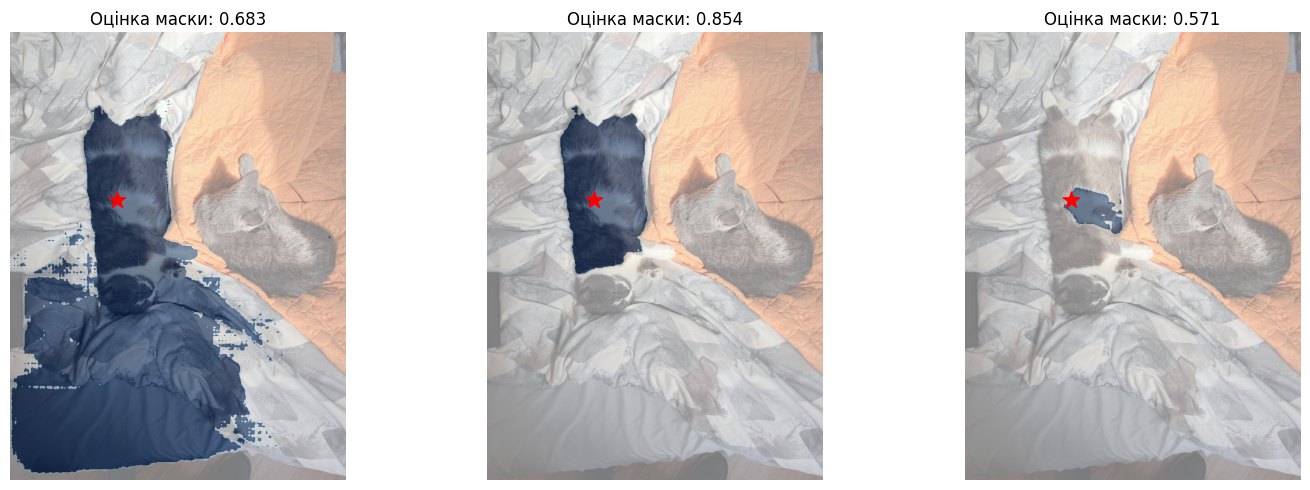

Кількість отриманих масок: 3


In [97]:

# Виконую сегментацію кота за допомогою SAM
predictor = SamPredictor(sam)

# Передаю фотографію моделі
predictor.set_image(img)

# Обираю точку всередині кота зліва
point_coords = np.array([[190, 300]])
point_labels = np.array([1])

# Отримую три варіанти маски
with torch.no_grad():
    masks, scores, _ = predictor.predict(
        point_coords=point_coords,
        point_labels=point_labels,
        multimask_output=True
    )

# Відображаю результати сегментації
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, mask, score in zip(axes, masks, scores):
    ax.imshow(img)
    ax.imshow(mask, alpha=0.5, cmap="Blues")
    ax.scatter(
        point_coords[:, 0],
        point_coords[:, 1],
        color="red",
        marker="*",
        s=150
    )
    ax.set_title(f"Оцінка маски: {score:.3f}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Кількість отриманих масок:", len(masks))


 Для сегментації задала точку з координатами (190, 300) всередині лівого кота. Модель створила три варіанти маски з оцінками 0.683, 0.854 та 0.571. Найкращий результат отримала друга маска з оцінкою 0.854. Вона виділила більшу частину тулуба кота, але не повністю охопила його контури.

### 4. Сегментація за кількома точками

Я додала позитивні точки на різних ділянках лівого кота та негативну точку на другому коті, щоб SAM не включала його в маску. Так я перевіряю, як підказки впливають на результат.

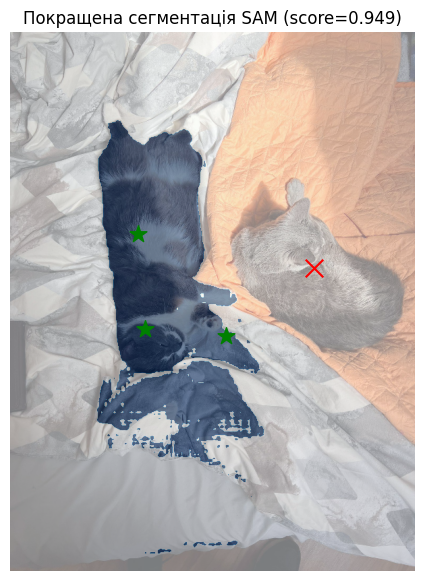

Найкраща оцінка: 0.949


In [98]:

# Покращую сегментацію за допомогою кількох точок
point_coords_new = np.array([
    [190, 300],  # Тулуб кота
    [200, 440],  # Нижня частина кота
    [320, 450],  # Біля голови кота
    [450, 350]   # Другий кіт (не включати)
])

point_labels_new = np.array([1, 1, 1, 0])

# Отримую оновлені маски
with torch.no_grad():
    masks_new, scores_new, _ = predictor.predict(
        point_coords=point_coords_new,
        point_labels=point_labels_new,
        multimask_output=True
    )

# Вибираю маску з найбільшою оцінкою
best_idx = np.argmax(scores_new)
best_mask = masks_new[best_idx]

plt.figure(figsize=(8, 7))
plt.imshow(img)
plt.imshow(best_mask, alpha=0.5, cmap="Blues")

for (x, y), label in zip(point_coords_new, point_labels_new):
    plt.scatter(
        x, y,
        c="green" if label == 1 else "red",
        marker="*" if label == 1 else "x",
        s=160
    )

plt.title(f"Покращена сегментація SAM (score={scores_new[best_idx]:.3f})")
plt.axis("off")
plt.show()

print("Найкраща оцінка:", round(scores_new[best_idx], 3))


Після додавання точок найвища прогнозована оцінка маски зросла з 0.854 до 0.949. Проте на зображенні залишилися помилки: до маски потрапила частина ковдри. Тому оцінка моделі сама по собі не означає, що контур виділений ідеально.


### 5. Сегментація за прямокутною рамкою

Далі я використала інший вид підказки це рамку навколо кота. Вона вказує моделі, де шукати потрібний об'єкт. Я порівняла результат із сегментацією за точка

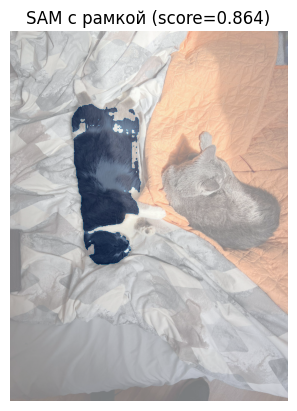

In [99]:
masks_box, scores_box, _ = predictor.predict(
    box=np.array([140, 170, 335, 535]), multimask_output=False)
plt.imshow(img); plt.imshow(masks_box[0], alpha=0.5, cmap="Blues"); plt.axis("off")
plt.title(f"SAM с рамкой (score={scores_box[0]:.3f})"); plt.show()

 Прогнозована оцінка маски становить 0.864, що нижче, ніж 0.949 при використанні кількох точок. Проте візуально результат кращий: маска більше не захоплює ковдру внизу зображення. Водночас маска неповна: у верхній частині є пропуски, а світла шерсть на лапах частково не виділена, оскільки вона схожа за кольором на ковдру. Отже, оцінка моделі не завжди відображає реальну точність сегментації, і результат потрібно перевіряти візуально. Для кращого результату можна поєднати рамку з додатковими позитивними точками на світлих ділянках шерсті.


### 7. Визначення координат для підказок

Щоб точніше вибрати місця для нових точок, я показала на фотографії сітку координат. Вона допоможе вказати ділянки кота, які модель пропускала.

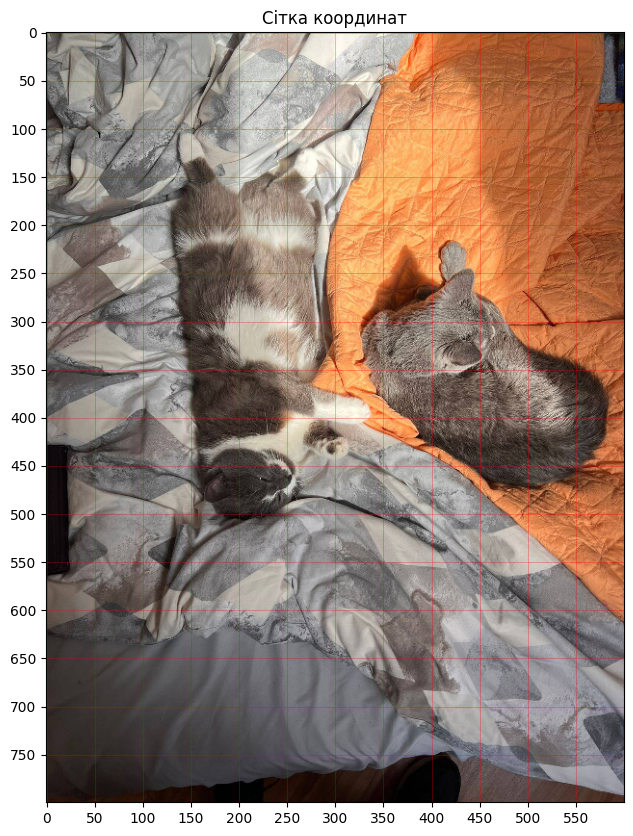

In [100]:
plt.figure(figsize=(8, 10))
plt.imshow(img)
plt.xticks(range(0, 600, 50))
plt.yticks(range(0, 800, 50))
plt.grid(True, color="red", alpha=0.4, linewidth=0.5)
plt.title("Сітка координат")
plt.show()

### 8. Рамка та додаткові точки

Я поєднала рамку з трьома позитивними точками на коті та однією негативною на ковдрі. Так модель отримала і приблизні межі об'єкта, і уточнення, які області потрібно включити або виключити.

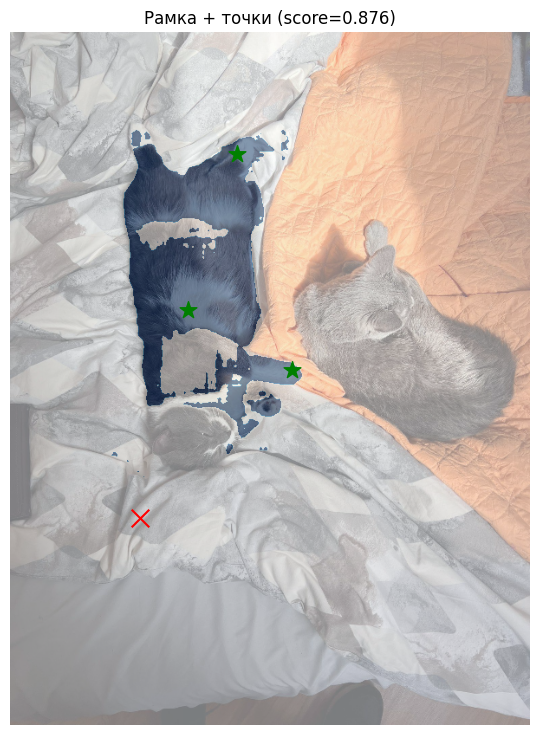

In [101]:
point_coords = np.array([[262, 140], [205, 320], [325, 390], [150, 560]])
point_labels = np.array([1, 1, 1, 0])        # остання точка негативна (ковдра)

masks_bp, scores_bp, _ = predictor.predict(
    box=np.array([120, 120, 345, 520]),
    point_coords=point_coords,
    point_labels=point_labels,
    multimask_output=False)

plt.figure(figsize=(7, 9))
plt.imshow(img); plt.imshow(masks_bp[0], alpha=0.5, cmap="Blues")
for (x, y), l in zip(point_coords, point_labels):
    plt.scatter(x, y, c="green" if l == 1 else "red",
                marker="*" if l == 1 else "x", s=160)
plt.axis("off")
plt.title(f"Рамка + точки (score={scores_bp[0]:.3f})")
plt.show()

Далі я поєднала прямокутну рамку з трьома позитивними точками та однією негативною точкою на ковдрі. Прогнозована оцінка маски становить 0.876. Порівняно з використанням лише рамки, маска краще охопила білі лапи кота, а ковдра внизу не потрапила до маски. Водночас у тілі залишилися світлі ділянки, які модель не віднесла до кота, а голова кота не була виділена, оскільки в цій області не було позитивної точки. Це показує, що результат SAM залежить від розташування підказок, а прогнозована оцінка не гарантує повноти маски


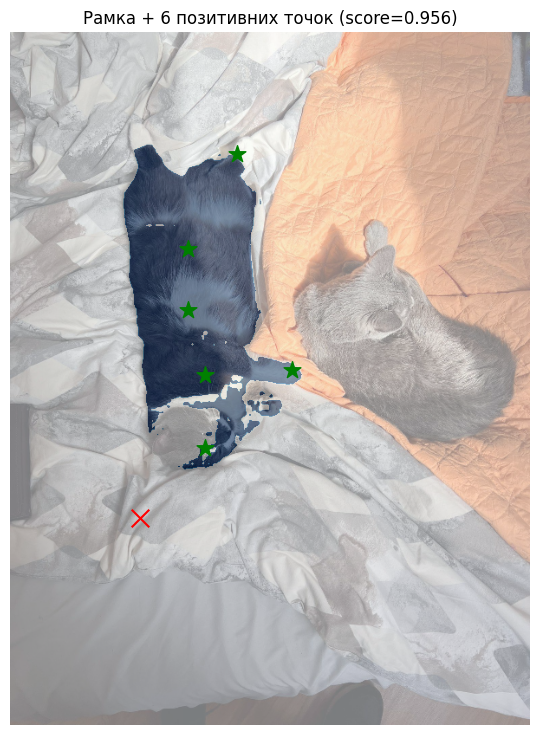

In [102]:
# Додаю шість позитивних точок на коті та одну негативну на ковдрі
point_coords = np.array([
    [262, 140], [205, 320], [325, 390],
    [205, 250], [225, 395], [225, 480],
    [150, 560]
])
point_labels = np.array([1, 1, 1, 1, 1, 1, 0])

masks_bp, scores_bp, _ = predictor.predict(
    box=np.array([120, 120, 345, 520]),
    point_coords=point_coords,
    point_labels=point_labels,
    multimask_output=False
)

plt.figure(figsize=(7, 9))
plt.imshow(img)
plt.imshow(masks_bp[0], alpha=0.5, cmap="Blues")
for (x, y), label in zip(point_coords, point_labels):
    plt.scatter(x, y,
                c="green" if label == 1 else "red",
                marker="*" if label == 1 else "x", s=160)
plt.axis("off")
plt.title(f"Рамка + 6 позитивних точок (score={scores_bp[0]:.3f})")
plt.show()

Нарешті я поєднала рамку із шістьма позитивними точками та однією негативною. Додаткові точки розташувала на ділянках, які модель раніше пропускала. Прогнозована оцінка маски становить **0.956**, це найвище значення серед перевірених варіантів. Маска стала повнішою, але частина контурів усе ще неточна. Отже, додаткові підказки допомогли покращити результат, хоча й не усунули всі помилки.

### 9. Порівняння результатів

Я порівняла кілька способів сегментації: одну точку, декілька точок, рамку та рамку разом із точками. Для однієї точки найвища прогнозована оцінка становила **0.854**, для кількох точок було **0.949**, для рамки **0.864**, для рамки з трьома позитивними точками **0.876**, а для рамки із шістьма позитивними точками **0.956**. Найвищу оцінку отримав останній варіант.

### 10. Пропозиції щодо покращення результатів

Під час роботи я помітила, що модель SAM не завжди точно визначає контури об'єкта. Навіть після додавання додаткових точок частина фону потрапила до маски.

Для покращення результатів я пропоную:

1. Використовувати більше позитивних і негативних точок, особливо біля контурів об'єкта, щоб точніше вказувати потрібну область.

2. Використовувати прямокутну рамку навколо об'єкта разом із точками-підказками, щоб модель краще відокремлювала його від фону.

3. Додати постобробку масок, наприклад видалення дрібних помилково виділених областей.

4. Порівняти SAM ViT-B з більшими моделями ViT-L та ViT-H, щоб оцінити можливе покращення сегментації та збільшення часу обробки.

На мою думку, для фотографій зі складним фоном найбільш корисним може бути поєднання точок-підказок і прямокутної рамки. 

### Висновок

У цій лабораторній роботі я ознайомилася з науковою статтею Segment Anything (2023) та використала відкритий код моделі SAM із GitHub.

Я встановила необхідні бібліотеки, завантажила модель SAM ViT-B і перевірила її роботу на фотографії двох котів. Для сегментації використала точки-підказки, прямокутну рамку та їх поєднання.

Спочатку найвища прогнозована оцінка маски становила 0.854. Після додавання точок вона зросла до 0.949, а найвищий результат 0.956 отримала при поєднанні рамки із шістьма позитивними та однією негативною точкою. Проте деякі контури залишилися неточними.

Також я запропонувала можливі способи покращення сегментації.

### Аналіз програмного коду та результатів

Для практичної частини я використала відкритий код Segment Anything з GitHub. Встановила необхідні бібліотеки PyTorch, OpenCV та segment-anything. Для запуску обрала модель SAM ViT-B, оскільки вона найменша серед трьох основних варіантів SAM і підходить для роботи на процесорі.

Спочатку я завантажила ваги моделі та фотографію з двома котами. Зображення зменшила до розміру 800 × 600 пікселів, щоб зменшити навантаження на ноутбук.

У коді використала `sam_model_registry` для створення моделі та `SamPredictor` для сегментації за точкою. Функція `set_image()` обробляє фотографію, а `predict()` створює маски відповідно до заданих координат.

Спочатку я вказала одну точку (190, 300) всередині лівого кота. Модель створила три маски з оцінками 0.683, 0.854 та 0.571. Найкращою за прогнозованою оцінкою стала друга маска (0.854), яка виділила більшу частину тулуба кота.

Потім я додала три позитивні точки для позначення потрібного об'єкта та одну негативну точку на другому коті. Після цього найвища прогнозована оцінка маски зросла до 0.949. Проте на зображенні видно, що модель також включила частину ковдри, тому сегментація залишилася неточною.

Таким чином, я перевірила роботу готового алгоритму та побачила, як кількість і розташування точок-підказок можуть впливати на результат сегментації.

Для порівняння я використала підказку у вигляді прямокутної рамки навколо кота. Прогнозована оцінка маски становить 0.864, що нижче, ніж 0.949 при використанні кількох точок. Проте візуально результат кращий: маска більше не захоплює ковдру внизу зображення. Водночас маска неповна: у верхній частині є пропуски, а світла шерсть на лапах частково не виділена, оскільки вона схожа за кольором на ковдру. Отже, оцінка моделі не завжди відображає реальну точність сегментації, і результат потрібно перевіряти візуально. Для кращого результату можна поєднати рамку з додатковими позитивними точками на світлих ділянках шерсті.

### Посилання на власний GitHub
https://github.com/asiaelfiturid/machine-learning-lab6-SAM